In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import spearmanr
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import math
import random

torch.manual_seed(0); np.random.seed(0)
train = datasets.MNIST('data', train=True, download=True)
test = datasets.MNIST('data', train=False, download=True)

In [2]:
class RotatedMNIST(Dataset):
    def __init__(self, base_dataset, min_digit: int, max_digit: int, min_rotation_deg: float, max_rotation_deg: float):
        self.base_dataset = base_dataset # the original MNIST dataset
        self.min_rotation_deg = min_rotation_deg
        self.max_rotation_deg = max_rotation_deg

        # Filter dataset using max_digit:
        valid_indices = torch.where((base_dataset.targets >= min_digit) & (base_dataset.targets <= max_digit))[0]
        self.indices = valid_indices.tolist()

    def __len__(self):
        # Return the length of the filtered dataset, not the whole dataset:
        return len(self.indices)

    def __getitem__(self, idx):
        # Map the requested index to the actual index in the dataset:
        real_idx = self.indices[idx]

        # Retrieve the base image tensor and digit label:
        img_tensor, digit_label = self.base_dataset[real_idx]

        # Generate a random angle (0 to max_rotation parameter value)
        angle_deg = random.uniform(self.min_rotation_deg, self.max_rotation_deg)
        angle_rad = math.radians(angle_deg)

        # Rotate the image tensor
        img_rotated = TF.rotate(img_tensor, angle_deg, fill=0)

        img_tensor = TF.to_tensor(img_rotated)

        # Convert continuous radian angle into a 2-value tensor (Sin and Cos)
        # $$$ Not using currently, but may consider if it improves accuracy
        # sin_cos_target = torch.tensor([math.sin(angle_rad), math.cos(angle_rad)], dtype=torch.float32)

        return img_tensor, digit_label, angle_rad, angle_deg

In [3]:
train_data = RotatedMNIST(
    base_dataset=train, 
    min_digit=0, # Defaults to 0 if not found
    max_digit=9, # Defaults to 9 if not found
    min_rotation_deg=0,
    max_rotation_deg=360
)
    
test_data = RotatedMNIST(
    base_dataset=test, 
    min_digit=0,
    max_digit=9,
    min_rotation_deg=0,
    max_rotation_deg=360
)

In [4]:
#Lets VAE pick a random point int the latent space without breaking the learning.
# Turns randomness into something the network can backpropagate
def reparameterize(mu, logvar):
    # Convert log variance into standard deviation
    # std = sqrt(variance)
    # Using logvar keeps training numerically stable
    std = torch.exp(0.5 * logvar)
    
    # Sample random noise from a standard normal distribution
    # This noise is what makes the VAE stochastic
    eps = torch.randn_like(std)
    
    # Create the latent vector z
    # z = mean + (random noise * standard deviation)
    # This lets gradients flow through mu and std during training
    return mu + eps * std

In [5]:
class TwoHeadedNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(),
                                  nn.Linear(784, 256),
                                  nn.ReLU(),
                                  nn.Linear(256, 64),
                                  nn.ReLU())
        self.digit_head = nn.Linear(64, 10)
        self.angle_head = nn.Linear(64, 24)

    def forward(self, x):
        h = self.body(x)
        return self.digit_head(h), self.angle_head(h)

In [6]:
class LayerVAE(nn.Module):
    def __init__(self, image_dim, latent_dim, hidden=128):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(image_dim, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, latent_dim)
        self.logvar = nn.Linear(hidden, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, image_dim), nn.ReLU())

    def forward(self, x):
        h = self.enc(x)
        mu, logvar = self.mu(h), self.logvar(h)
        z = reparameterize(mu, logvar) if self.training else mu
        recon = self.dec(z)
        return recon, mu, logvar

In [7]:
def layer_vae_loss(recon, h, mu, logvar, beta):
    rec = F.mse_loss(recon, h, reduction='sum') / h.size(0)
    kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / h.size(0)
    return rec + beta * kl

In [8]:
# Records the activation layer and runs it through the frozen network.
@torch.no_grad()
def get_acts(net, loader):
    net.eval(); H1, H2, D, A = [], [], [], []
    for imgs, digits, _, angles in loader:
        H1.append(net.body[:3](imgs)); H2.append(net.body[:5](imgs))
        D.append(digits); A.append(angles)
    return torch.cat(H1), torch.cat(H2), torch.cat(D), torch.cat(A)

In [9]:
net = TwoHeadedNN()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

from torch.utils.data import TensorDataset

for epoch in range(8):
    net.train()
    for images, digit_labels, _, angles in train_loader:
        angle_labels = (angles // 15).long().clamp(max=23)
        opt.zero_grad()
        digit_output, angle_output = net(images)
        loss = F.cross_entropy(digit_output, digit_labels) + F.cross_entropy(angle_output, angle_labels)
        loss.backward()
        opt.step()

# 1. Freeze the trained TwoHeadedNN
net.eval()
for p in net.parameters():
    p.requires_grad = False

# 2. Extract layer activations
H1_tr, H2_tr, Y_tr, A_tr = get_acts(net, train_loader)
H1_te, H2_te, Y_te, A_te = get_acts(net, test_loader)

# 3. Train a LayerVAE on a layers activations
def train_layer_vae(H, latent_dim, beta=1.0, epochs=20):
    vae = LayerVAE(H.size(1), latent_dim)
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(H), batch_size=256, shuffle=True)
    for epoch in range(epochs):
        vae.train()
        total = 0
        for (h,) in loader:
            recon, mu, logvar = vae(h)
            loss = layer_vae_loss(recon, h, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * h.size(0)
        print(f'  epoch {epoch+1}: loss {total / len(H):.3f}')
    return vae.eval()

latent_dim = 8
vae_h1 = train_layer_vae(H1_tr, latent_dim)   # Layer 1: 256 -> 8 -> 256
vae_h2 = train_layer_vae(H2_tr, latent_dim)   # Layer 2: 64  -> 8 -> 64

# 4. Constrained representations on the test set
with torch.no_grad():
    h1_recon, mu1, _ = vae_h1(H1_te)
    h2_recon, mu2, _ = vae_h2(H2_te)


  epoch 1: loss 125.276
  epoch 2: loss 88.557
  epoch 3: loss 82.934
  epoch 4: loss 80.263
  epoch 5: loss 78.618
  epoch 6: loss 77.403
  epoch 7: loss 76.481
  epoch 8: loss 75.709
  epoch 9: loss 75.028
  epoch 10: loss 74.429
  epoch 11: loss 73.902
  epoch 12: loss 73.513
  epoch 13: loss 73.092
  epoch 14: loss 72.740
  epoch 15: loss 72.386
  epoch 16: loss 72.104
  epoch 17: loss 71.854
  epoch 18: loss 71.588
  epoch 19: loss 71.359
  epoch 20: loss 71.154
  epoch 1: loss 254.609
  epoch 2: loss 118.316
  epoch 3: loss 102.886
  epoch 4: loss 95.859
  epoch 5: loss 92.192
  epoch 6: loss 89.544
  epoch 7: loss 87.453
  epoch 8: loss 85.567
  epoch 9: loss 84.112
  epoch 10: loss 82.826
  epoch 11: loss 81.748
  epoch 12: loss 80.837
  epoch 13: loss 80.034
  epoch 14: loss 79.296
  epoch 15: loss 78.752
  epoch 16: loss 78.128
  epoch 17: loss 77.575
  epoch 18: loss 77.107
  epoch 19: loss 76.711
  epoch 20: loss 76.331


R^2, checks how much of the layer survives. Essentially we are comparing the VAE's error to the baseline.
We can see Layer 1 struggling since it goes from 256 neurons to 8 neurons compared to 64 to 8.


Ratio is the share of the variation the VAE failed to capture. When we subtract it by 1 aka 1 - the similarity calc, we get the variation it kept.

In [10]:
N_PER_DIGIT = 200
rng = np.random.default_rng(0)
labels_all = test.targets.numpy()
idx = np.sort(np.concatenate([rng.choice(np.where(labels_all == d)[0], N_PER_DIGIT, replace=False)
                              for d in range(10)]))
ang_s = rng.uniform(0, 360, size=len(idx))     # one fixed angle per image

imgs = torch.stack([TF.to_tensor(TF.rotate(test[i][0], float(a), fill=0)) for i, a in zip(idx, ang_s)])
with torch.no_grad():
    H1_s = net.body[:3](imgs)    # (2000, 256)
    H2_s = net.body[:5](imgs)    # (2000, 64)
y_s = labels_all[idx]

np.savez('rotated_activations.npz', X=imgs.flatten(1).numpy(), H1=H1_s.numpy(), H2=H2_s.numpy(), y=y_s, angle=ang_s)
torch.save(net.state_dict(), 'twoheaded_nn.pt')

print('H1:', tuple(H1_s.shape), '| H2:', tuple(H2_s.shape), '| per digit:', np.bincount(y_s))
print('Dead units: layer 1 =', int((H1_s.max(0).values == 0).sum()), '| layer 2 =', int((H2_s.max(0).values == 0).sum()))

H1: (2000, 256) | H2: (2000, 64) | per digit: [200 200 200 200 200 200 200 200 200 200]
Dead units: layer 1 = 5 | layer 2 = 6


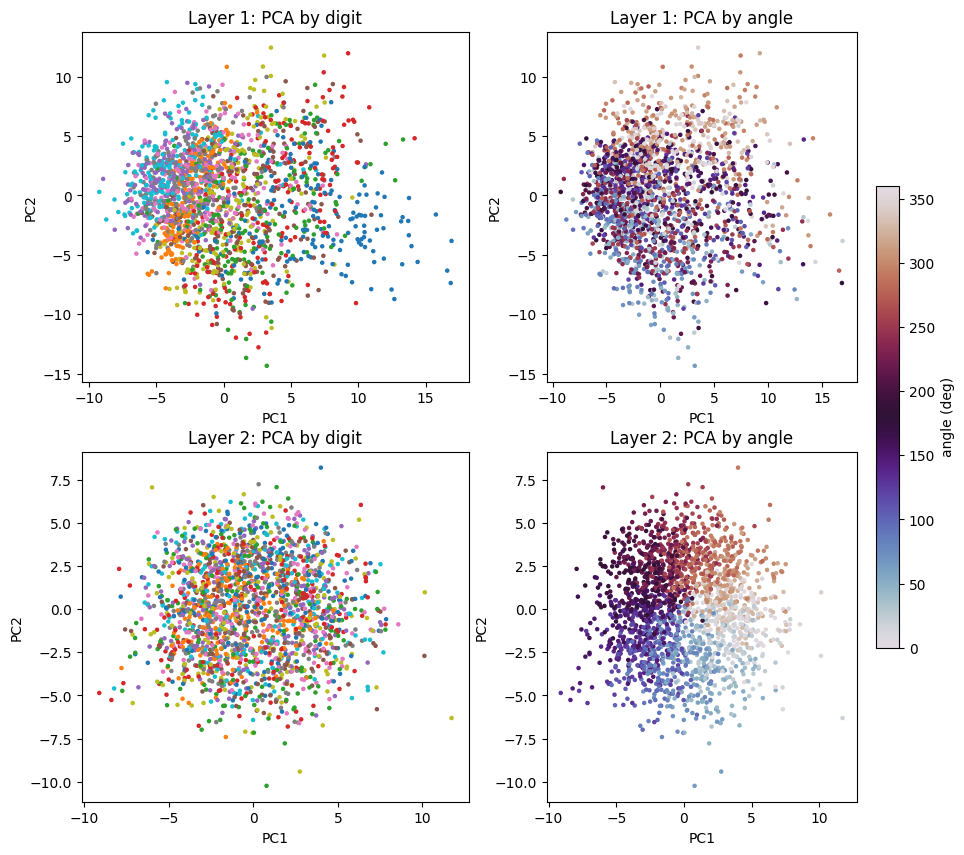

In [11]:
def zscore(X):
    X = np.asarray(X, dtype=float)
    sd = X.std(axis=0); sd[sd == 0] = 1.0
    return (X - X.mean(axis=0)) / sd

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for r, (H, title) in enumerate([(H1_s, 'Layer 1'), (H2_s, 'Layer 2')]):
    s = PCA(2).fit_transform(zscore(H))
    axes[r, 0].scatter(*s.T, c=y_s, cmap='tab10', s=5)
    sc = axes[r, 1].scatter(*s.T, c=ang_s, cmap='twilight', vmin=0, vmax=360, s=5)
    axes[r, 0].set(title=f'{title}: PCA by digit', xlabel='PC1', ylabel='PC2')
    axes[r, 1].set(title=f'{title}: PCA by angle', xlabel='PC1', ylabel='PC2')
fig.colorbar(sc, ax=axes[:, 1], label='angle (deg)', shrink=0.6)
plt.show()

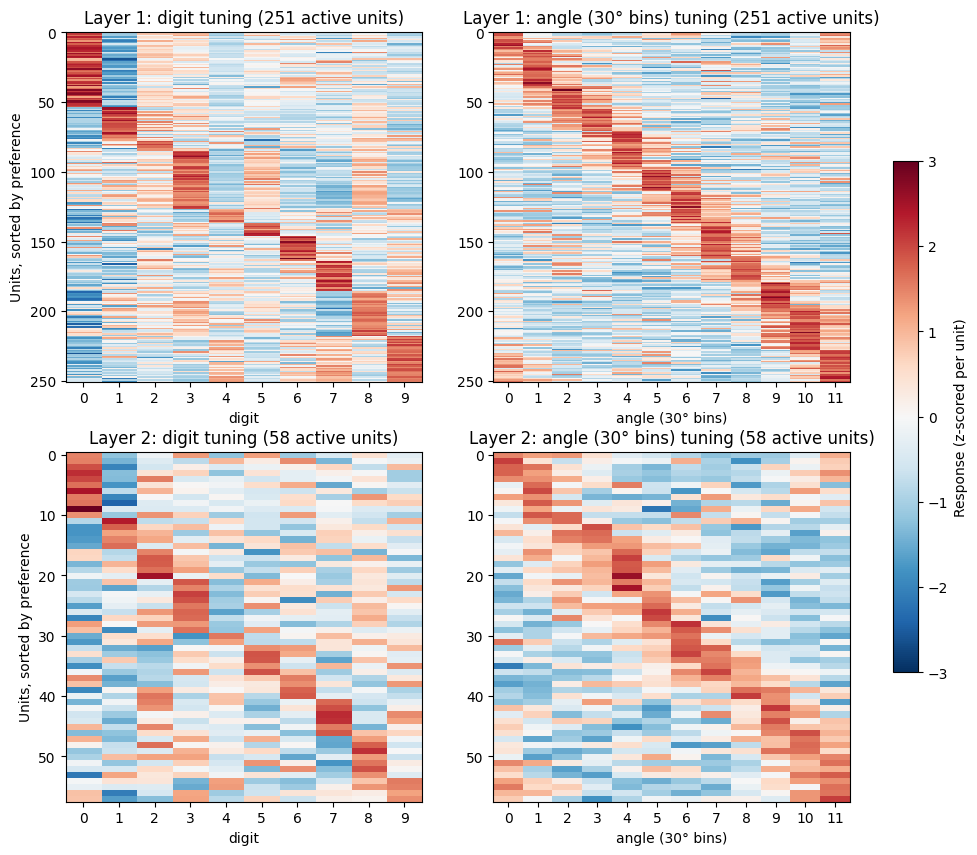

In [12]:
ang_bin = (ang_s // 30).astype(int)   # 12 bins of 30°

def tuning_map(H, labels, n):
    H = np.asarray(H)
    alive = H.max(axis=0) > 0
    t = np.array([H[labels == k][:, alive].mean(axis=0) for k in range(n)]).T   # units x conditions
    t = t[np.argsort(t.argmax(axis=1), kind='stable')]                          # sort by preferred condition
    return (t - t.mean(1, keepdims=True)) / (t.std(1, keepdims=True) + 1e-12), alive.sum()

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for r, (H, title) in enumerate([(H1_s, 'Layer 1'), (H2_s, 'Layer 2')]):
    for c, (labels, n, what) in enumerate([(y_s, 10, 'digit'), (ang_bin, 12, 'angle (30° bins)')]):
        t, n_alive = tuning_map(H, labels, n)
        im = axes[r, c].imshow(t, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
        axes[r, c].set(title=f'{title}: {what} tuning ({n_alive} active units)', xlabel=what, xticks=range(n))
    axes[r, 0].set_ylabel('Units, sorted by preference')
fig.colorbar(im, ax=axes, label='Response (z-scored per unit)', fraction=0.03)
plt.show()

Training VAE on Layer 1, beta=1.0...
  epoch 1: loss 241.572
  epoch 2: loss 237.520
  epoch 3: loss 236.947
  epoch 4: loss 236.501
  epoch 5: loss 236.190
  epoch 6: loss 235.939
  epoch 7: loss 235.727
  epoch 8: loss 235.546
  epoch 9: loss 235.320
  epoch 10: loss 235.187
  epoch 11: loss 235.037
  epoch 12: loss 234.798
  epoch 13: loss 234.672
  epoch 14: loss 234.553
  epoch 15: loss 234.422
  epoch 16: loss 234.339
  epoch 17: loss 234.247
  epoch 18: loss 234.137
  epoch 19: loss 234.023
  epoch 20: loss 233.963
Training VAE on Layer 1, beta=20.0...
  epoch 1: loss 252.536
  epoch 2: loss 252.031
  epoch 3: loss 252.014
  epoch 4: loss 252.008
  epoch 5: loss 252.007
  epoch 6: loss 252.003
  epoch 7: loss 252.008
  epoch 8: loss 252.011
  epoch 9: loss 252.004
  epoch 10: loss 252.017
  epoch 11: loss 252.007
  epoch 12: loss 252.005
  epoch 13: loss 252.009
  epoch 14: loss 252.003
  epoch 15: loss 252.006
  epoch 16: loss 252.004
  epoch 17: loss 251.999
  epoch 18: loss 2

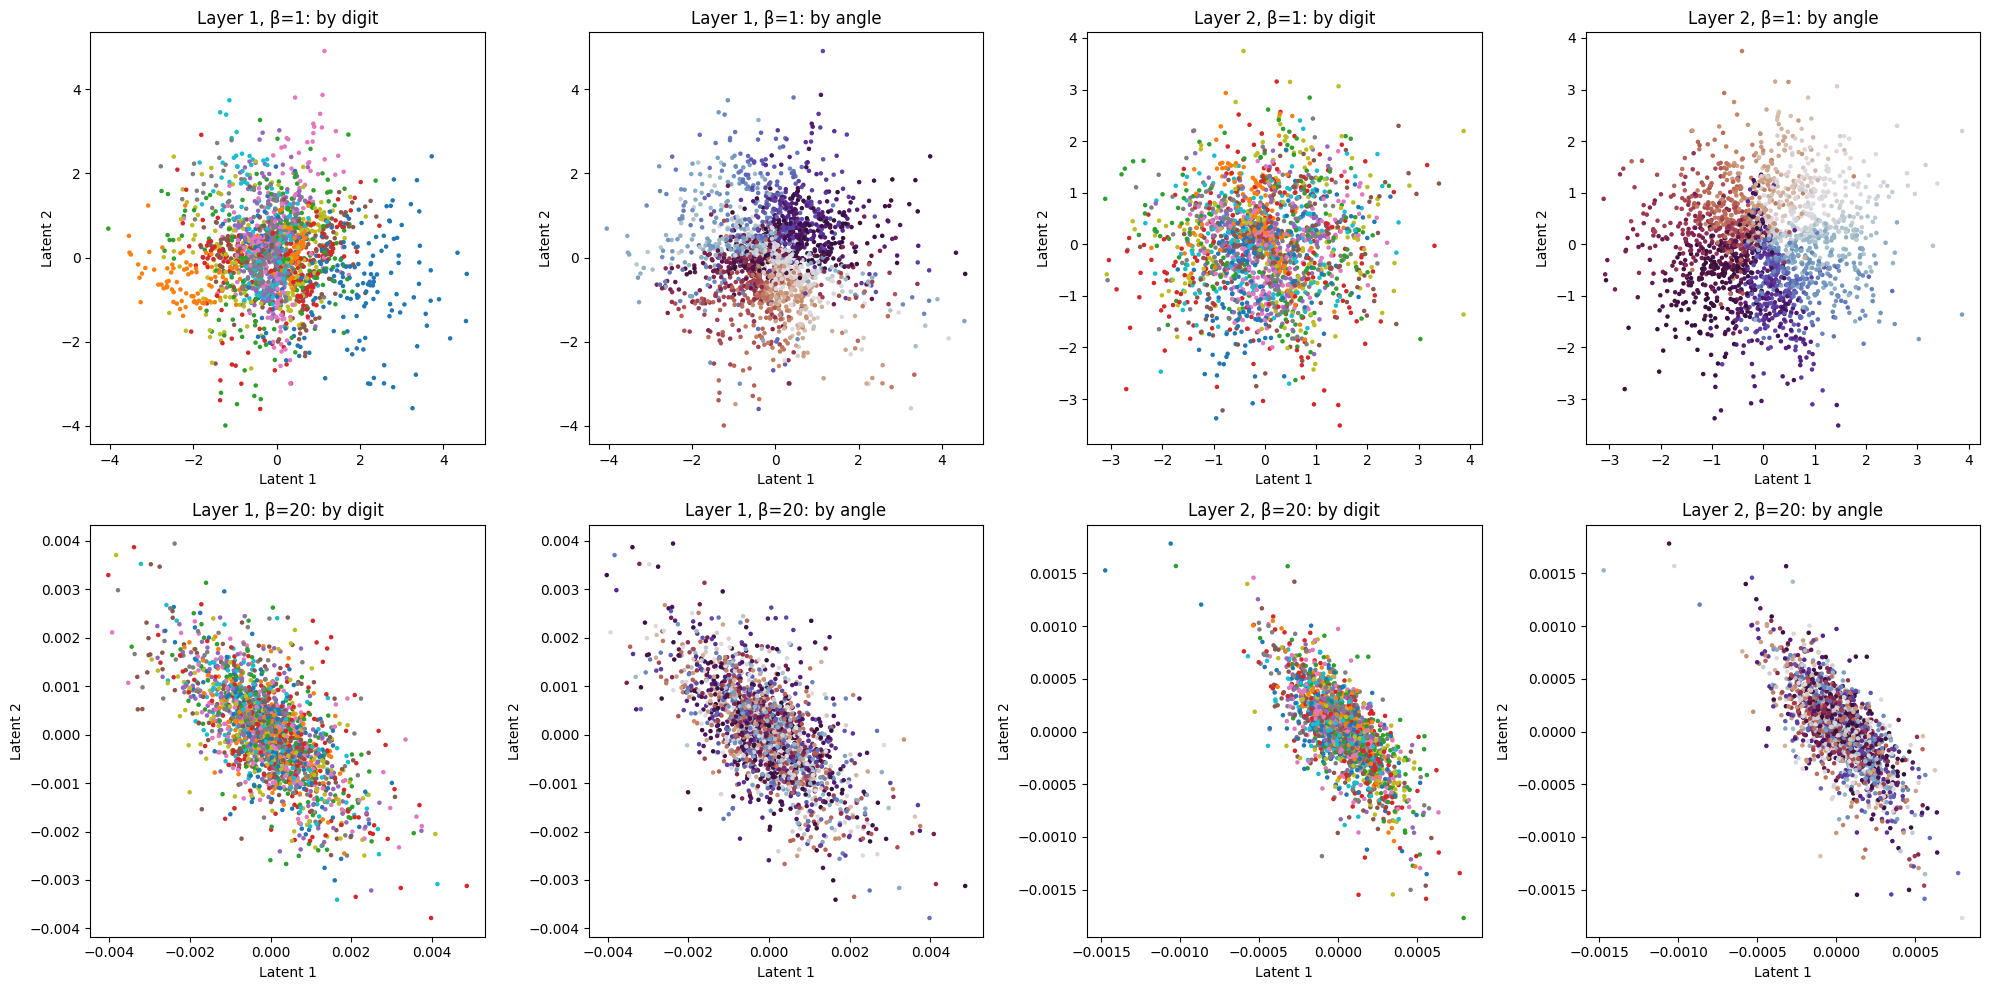

In [13]:
def fit_vae_2d(H_train, H_eval, beta, epochs=20):
    """Z-score with training stats, train a 2-D LayerVAE, return the latent centers and an un-z-scored reconstruction."""
    m = H_train.mean(0); s = H_train.std(0); s[s == 0] = 1.0
    vae = train_layer_vae((H_train - m) / s, latent_dim=2, beta=beta, epochs=epochs)
    with torch.no_grad():
        rec, mu, _ = vae((H_eval - m) / s)
    return mu.numpy(), rec * s + m        # rec back in original activation units

betas = [1.0, 20.0]
latents, recons = {}, {}
for name, Htr, Hs in [('Layer 1', H1_tr, H1_s), ('Layer 2', H2_tr, H2_s)]:
    for b in betas:
        print(f'Training VAE on {name}, beta={b}...')
        latents[(name, b)], recons[(name, b)] = fit_vae_2d(Htr, Hs, b)

fig, axes = plt.subplots(len(betas), 4, figsize=(20, 5 * len(betas)))
for r, b in enumerate(betas):
    for c, name in enumerate(['Layer 1', 'Layer 2']):
        z = latents[(name, b)]
        axes[r, 2*c].scatter(*z.T, c=y_s, cmap='tab10', s=5)
        axes[r, 2*c + 1].scatter(*z.T, c=ang_s, cmap='twilight', vmin=0, vmax=360, s=5)
        axes[r, 2*c].set(title=f'{name}, β={b:g}: by digit', xlabel='Latent 1', ylabel='Latent 2')
        axes[r, 2*c + 1].set(title=f'{name}, β={b:g}: by angle', xlabel='Latent 1', ylabel='Latent 2')
plt.tight_layout(); plt.show()

In [14]:
def r2(H, R):
    return 1 - ((H - R) ** 2).sum() / ((H - H.mean(0)) ** 2).sum()

print('Layer 1 R²:', r2(H1_te, h1_recon).item())
print('Layer 2 R²:', r2(H2_te, h2_recon).item())

Layer 1 R²: 0.7146501541137695
Layer 2 R²: 0.8518690466880798


Digit, Angle, Angle with 15 degrees

In [15]:
@torch.no_grad()
def head_acc(h2):
    dp = net.digit_head(h2).argmax(1)
    ap = net.angle_head(h2).argmax(1)
    ac = (A_te // 15).long().clamp(max=23)
    diff = (ap - ac).abs(); diff = torch.minimum(diff, 24 - diff)
    return [(dp == Y_te).float().mean().item(),
            (ap == ac).float().mean().item(),
            (diff <= 1).float().mean().item()]

with torch.no_grad():
    baseline = head_acc(H2_te)                    # unconstrained
    from_h1  = head_acc(net.body[3:](h1_recon))   # layer 1 compressed, rest of network normal
    from_h2  = head_acc(h2_recon)                 # layer 2 compressed

print('Baseline:      ', baseline)
print('h1 constrained:', from_h1)
print('h2 constrained:', from_h2)

Baseline:       [0.9002000093460083, 0.7096999883651733, 0.9401000142097473]
h1 constrained: [0.7721999883651733, 0.4113999903202057, 0.8396000266075134]
h2 constrained: [0.8184000253677368, 0.5737000107765198, 0.9312999844551086]


Reshape the activation vector into a square. The plot is displaying activation heatmaps, but lowk I don't really think it is useful for display.

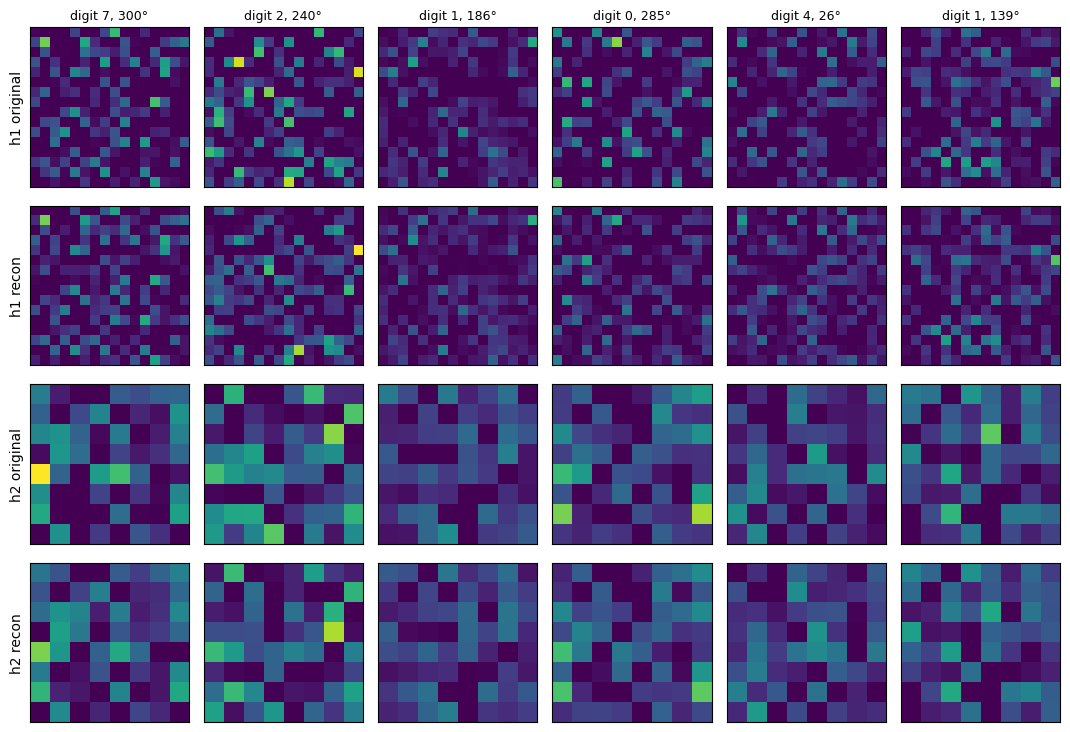

In [16]:
n = 6
fig, axes = plt.subplots(4, n, figsize=(n * 1.8, 7.5))
rows = [(H1_te, 16, 'h1 original'), (h1_recon, 16, 'h1 recon'),
        (H2_te, 8,  'h2 original'), (h2_recon, 8,  'h2 recon')]

for r, (H, side, name) in enumerate(rows):
    vmax = max(H1_te[:n].max(), h1_recon[:n].max()) if side == 16 else max(H2_te[:n].max(), h2_recon[:n].max())
    for i in range(n):
        axes[r, i].imshow(H[i].reshape(side, side), cmap='viridis', vmin=0, vmax=vmax)
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])
        if r == 0:
            axes[r, i].set_title(f'digit {Y_te[i].item()}, {A_te[i].item():.0f}°', fontsize=9)
    axes[r, 0].set_ylabel(name, fontsize=10)
plt.tight_layout(); plt.show()